# 01 · Preprocessing — Peng 2019 PDAC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, and characterise the manifold. Pancreatic ductal adenocarcinoma (PDAC) is an
epithelial malignancy; Peng et al. profiled 24 primary PDAC + 11 control samples on 10x and
annotated a malignant ductal compartment. Every tunable choice is **derived from this dataset**,
not inherited from the Puram anchor. **Gate 1** (batch mixing + manifold continuity) is decided on
the regenerated embedding itself with a per-neighbourhood metric (iLISI across a theta sweep), not a
scalar. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # e.g. 'Peng2019_Pancreas-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
name_raw = re.sub(r'-\d+$', '', name)                   # strip the re-run '-1' suffix -> raw folder
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_raw)                  # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads (-1)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| raw folder: Data_'+name_raw, '| category:', cat)

dataset: Peng2019_Pancreas-1 | raw folder: Data_Peng2019_Pancreas | category: Pancreas


### Load malignant compartment
Peng et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit label
(the publication's malignancy call, epithelial ductal-carcinoma cells); the loader exposes it as
`celltype`, so the malignancy call here is `celltype == 'Malignant'`, taken directly (per protocol:
use the publication's calls). Expression is 10x UMI counts, normalised + `log1p` by the loader.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

full atlas: (27953, 18302)
malignant: (7945, 18302) | samples: 16
expression: X max 8.42 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and spillover). Here the largest ratio (998→432, ×2.31)
sits **mid-distribution between two substantially-sized tumours**, not at a low-count spillover
cliff — cutting there would discard 12/16 samples that each carry >100 malignant cells. The
clean-count-gap premise (02_train C3) is therefore **not met**. We fall back to the protocol's
≥100-cell floor; every sample clears it (min 103), so all 16 are retained — matching the
same-tissue PDAC precedent (Steele/Lin/Moncada 2020, all samples kept).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100
boundary = int(vals[gap+1])
if gap == 0 or boundary > FLOOR*2:
    print(f'gap boundary ({boundary}) is not low-count spillover -> premise unmet, '
          f'fall back to >= {FLOOR}-cell floor')
    thresh = FLOOR
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[keep].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [1686 1439 1368  998  432  291  282  250  215  198  193  146  122  115
  107  103]
largest multiplicative gap: 998 -> 432 (ratio 2.31) at rank 3
gap boundary (432) is not low-count spillover -> premise unmet, fall back to >= 100-cell floor
kept 16/16 samples (min per-sample = 103) -> 7945 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing): we take the
theta past which mixing plateaus. PDAC malignant cells are strongly patient-specific (distinct CNVs
/ classical-basal balance), so the strongest integration is chosen. PC count (20), UMAP spread
(1.3) and `n_neighbors` (30) follow the 10x precedents (Kürten / Sun / Lee / Steele, comparable
cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1288 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1288
2026-08-05 17:46:23,378 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:46:24,461 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:46:24,508 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 17:46:26,586 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 17:46:28,608 - harmonypy - INFO - Iteration 3 of 30
2026-08-05 17:46:30,452 - harmonypy - INFO - Iteration 4 of 30
2026-08-05 17:46:32,315 - harmonypy - INFO - Converged after 4 iterations
2026-08-05 17:46:32,601 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:46

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping a
continuous manifold.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
c_ = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
s_ = np.linalg.svd(c_, full_matrices=False)[1]
print('manifold aspect (major/minor UMAP std): %.2f' % (s_[0]/s_[1]))

removed 0 cells in 0 detached islands
manifold aspect (major/minor UMAP std): 1.17


### Compartment & cell-cycle characterisation (biology before the Gate-1 GO)
The Kürten lobe-identity fork requires settling each sub-region's biology (signatures **and** cell
cycle) before certifying continuity. Low-resolution Leiden (res=0.15) recovers the manifold's
lobes; here it returns a **single transcriptional body** (one cluster). PDAC is almost entirely
non-cycling (~4% cycling), so there is no proliferation lobe to scope out. We score the three
developmental modules against the shared union pool (canonically re-scored in 02) purely to (i)
check cell cycle is not a module confound and (ii) orient the house layout. Moffitt classical/basal
scores confirm the compartment is classical-predominant ductal carcinoma (Peng et al. 2019).

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
# developmental modules (union control pool) — for confound check + orientation only
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes')
# Moffitt classical / basal (Moffitt et al. 2015)
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','CEACAM5','TSPAN8','ST6GALNAC1','AGR2',
             'CLRN3','LYZ','MYO1A','CDH17','VSIG2','BTNL8','FAM3D','SPINK4']
basal = ['KRT17','KRT15','KRT6A','KRT6C','KRT5','KRT7','KRT14','TP63','S100A2','SPRR3','SPRR1B',
         'LY6D','SCEL','FAM83A','SLC2A1','CST6','DHRS9','LEMD1','GPR87']
for nm,gs in [('classical',classical),('basal',basal)]:
    gg = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, gg, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(gg)}/{len(gs)} genes | mean {adata.obs[nm+"_score"].mean():+.3f}')
adata.obs['compartment'] = 'Ductal (malignant)'

lobe sizes: {'0': 7945}
overall cycling fraction: 0.066
Gast: 77/81 genes
pSom: 90/98 genes
Crest: 100/104 genes
classical: 17/17 genes | mean +0.502
basal: 19/19 genes | mean +0.000


### Cell cycle is not a developmental-module confound
Correlate each module (raw + graph-smoothed) with the cycling score. All correlations are weak
(|rho| ≤ 0.24 smoothed), the Crest-high decile is only marginally enriched for cyclers, and the
pSom↔Crest spatial anti-correlation is unchanged when cyclers are excluded — so cell cycle is
orthogonal to the developmental signatures and the **whole manifold** is carried forward (no
scoping; Steele/Bischoff/Sun precedent).

In [8]:
from scipy.stats import spearmanr
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling: rho={rho:+.3f}')
cyc_mask = adata.obs['cell_cycle_phase'].isin(['G2/M','Intermediate']).values
crest_hi = (adata.obs['Crest_sm']>=adata.obs['Crest_sm'].quantile(0.9)).values
print(f'Crest-high decile cycling fraction = {cyc_mask[crest_hi].mean():.2f} (baseline {cyc_mask.mean():.2f})')
subnc = adata[~cyc_mask]
r_all = np.corrcoef(adata.obs['pSom_sm'], adata.obs['Crest_sm'])[0,1]
r_nc  = np.corrcoef(subnc.obs['pSom_sm'], subnc.obs['Crest_sm'])[0,1]
print(f'pSom_sm-Crest_sm spatial r: all {r_all:+.2f} | excl. cyclers {r_nc:+.2f} (unchanged -> not a confound)')

  Gast_sm vs cycling: rho=-0.230
  pSom_sm vs cycling: rho=-0.092
  Crest_sm vs cycling: rho=+0.243
Crest-high decile cycling fraction = 0.08 (baseline 0.04)
pSom_sm-Crest_sm spatial r: all -0.61 | excl. cyclers -0.64 (unchanged -> not a confound)


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all panels are shown after a
single **rigid rotation** to the house horizontal layout (distance-preserving — *not* a
re-embedding). Angle = the manifold's axis of maximal variance; sign puts the developmental origin
(pSom-high / Crest-low pole) on the left. Derived **once here**, stored as `X_umap_lin`, re-used
unchanged by 02/03/04 so every deliverable UMAP shares one orientation (binding).

In [9]:
S2 = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S2 = A @ S2
origin_score = S2[:,0] - S2[:,1]                          # pSom-high / Crest-low = origin
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0)
_, _, vt = np.linalg.svd(cc, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],
               [np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = cc @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'pSom-high origin pole on left; stored as X_umap_lin')

house orientation: rigid rotation -21.9deg (distances preserved), pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
**Read on the regenerated embedding** (`samples.pdf` below), corroborated by a per-neighbourhood
iLISI across the theta sweep. The 16 samples intermix across one continuous connected component (0
detached islands), aspect ≈ 1.1 (a single compact body, not a patient archipelago). → **Gate 1 =
GO**.

In [10]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples on one connected component after island removal.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 5.34 of 16 samples
16 samples on one connected component after island removal.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data

In [11]:
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        keep_num = s.notna().sum() > 0 and conv.notna().sum() >= 0.9*s.notna().sum()
        adata.obs[col] = conv if keep_num else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7945, 17154)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 7945


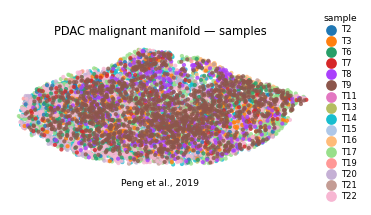

In [12]:
# House style (3.5,1.5) horizontal strip, size=30; colour = sample. Intermixing across the
# body is the Gate-1 evidence, shown on the house orientation (X_umap_lin) shared with 02/03/04.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])